# Below is the actual model and the pathfinding logic. 
## It currently uses a greedy algorithm, though I want to implement some smarter logic in the future like predicting probable routes

In [15]:
import re
import requests
from sentence_transformers import SentenceTransformer, util
from bs4 import BeautifulSoup
from urllib.parse import urljoin
import time
link_format = "https://en.wikipedia.org/wiki/"

def Wikibot(item, target):
    print(f"Navigating from {item} to {target}")
    failed_run = False
    url = link_format + item

    
    target_url = link_format + target


    target_slug = target.replace('_', ' ')
    current_word = item
    model = SentenceTransformer('all-mpnet-base-v2')

    clicks = 0
    visited_slugs = [item]
    #header set
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
        "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8",
        "Accept-Language": "en-US,en;q=0.5",
        "Accept-Encoding": "gzip, deflate, br",
        "Connection": "keep-alive",
        "Upgrade-Insecure-Requests": "1"
    }

    average_times = 0
    start_time = time.perf_counter()
    current_time = start_time

    #List of go to hubs
    list_of_hubs = ['United States', 'Japan', 'Germany', 'United Kingdom', 'Beetle', 'Athlete']
    hub_vectors = []
    #Go to hub only if there is not a quick path of 2 links or less. For now, calculate cosine similarities and have them on hand.



    target_vector = model.encode(target, convert_to_tensor=True)
    link_vectors = model.encode(list_of_hubs, convert_to_tensor=True)
    cosine_scores = util.cos_sim(target_vector, link_vectors)[0]
        
    pairs = zip(list_of_hubs, cosine_scores)
        
        # Use key to look at index 1 (the score)
    best_hub, best_hub_score = max(pairs, key=lambda item: item[1])
            
    print(f"Top Hub: {best_hub} with Score: {best_hub_score.item():.4f}")


    while(target.lower() != current_word.lower()):
        
        print(f"\n--- Navigating to: {url} ---")
        
        # FIX 1: Fetch the HTML content for the NEW url on every loop iteration
        # response: html of the page
        try:
            response = requests.get(url, headers=headers, timeout=10)
            response.raise_for_status()
        except requests.exceptions.RequestException as e:
            print(f"Failed to fetch {url}: {e}")
            failed_run = True
            break


        # 3. Parse HTML (response) using Beautiful Soup
        soup = BeautifulSoup(response.text, "html.parser")

        # 4. Find all <a> tags that have an 'href' attribute
        links = soup.find_all("a", href=True)

        myurls = []

        # 5. Extract and print the links
        print(f"Found {len(links)} links on the page\n")
        for link in links:
            href = link["href"]
            #assemble url
            full_url = urljoin(url, href)
            
            # Get the text associated with the link
            link_text = link.get_text(strip=True)
            
            #print(f"Text: {link_text} -> Link: {full_url}")
            if "https://en.wikipedia.org/wiki/" in full_url:
                myurls.append(full_url)
            
        slugs = []
        for url in myurls:
            slug = url.split("/wiki/")[1]
            slug = slug.replace("_", " ")
            if "#" not in url and "(identifier)" not in url:
                if ":" not in slug:
                    if "?" not in slug:
                        if slug not in visited_slugs:
                            slugs.append(slug)
                            #print(url)
        

        
                

        slugs = [slug.replace('_', ' ') for slug in slugs]


        #Cosine Similarity
        
        target_vector = model.encode(target, convert_to_tensor=True)
        link_vectors = model.encode(slugs, convert_to_tensor=True)
        cosine_scores = util.cos_sim(target_vector, link_vectors)[0]

        pairs = zip(slugs, cosine_scores)



        # Use key to look at index 1 (the score)
        best_slug, best_score = max(pairs, key=lambda item: item[1])
        
        print(f"Top Slug: {best_slug} with Score: {best_score.item():.4f}")

        url = link_format + best_slug
        current_word = best_slug
        
        visited_slugs.append(best_slug)
        print(visited_slugs)
        clicks += 1

        if (best_score != 1.0000):
            print (f"{best_score} is not equal to 1")

        link_time = time.perf_counter()
        average_times += link_time - current_time
        if average_times > 60:
            failed_run = True
            break
        current_time = link_time
        


        

    for slug, score in pairs:
        print(f"Similarity between '{target}' and '{slug}': {score.item():.4f}")




    end_time = time.perf_counter()
    execution_time = end_time-start_time
    average_times = average_times/clicks
    print(f"Reached {target_slug} from {item} in {clicks} clicks and {execution_time} seconds!")
    print(f"Average Time: {average_times} seconds")
    if failed_run == False:
        return average_times, execution_time, clicks
    elif failed_run == True:
        return False
    return average_times, execution_time, clicks

print(Wikibot("Benjamin Franklin", "Franklin D. Roosevelt"))










Navigating from Benjamin Franklin to Franklin D. Roosevelt


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 22101.00it/s]


Top Hub: Athlete with Score: 0.1831

--- Navigating to: https://en.wikipedia.org/wiki/Benjamin Franklin ---
Found 5086 links on the page

Top Slug: Franklin D. Roosevelt with Score: 1.0000
['Benjamin Franklin', 'Franklin D. Roosevelt']
0.9999999403953552 is not equal to 1
Reached Franklin D. Roosevelt from Benjamin Franklin in 1 clicks and 3.4180215829983354 seconds!
Average Time: 3.4180193331558257 seconds
(3.4180193331558257, 3.4180215829983354, 1)


# Below generates a list of the most popular Wikipedia pages. 
(This data is outdated as of around 2023, as Wikipedia stopped updating the page.)

In [ ]:
from urllib.parse import urljoin
url = 'https://en.wikipedia.org/wiki/Wikipedia:Popular_pages'
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,image/webp,*/*;q=0.8",
    "Accept-Language": "en-US,en;q=0.5",
    "Accept-Encoding": "gzip, deflate, br",
    "Connection": "keep-alive",
    "Upgrade-Insecure-Requests": "1"
}
response = requests.get(url, headers = headers)
soup = BeautifulSoup(response.text, "html.parser")

all_headings = [
    'Universe', 'Earth', 'Life',
    'Civilization', 'People', 'Entertainment', 'Events'
]


universe_slugs = []
earth_slugs = []
life_slugs = []
civil_slugs = []
people_slugs = []
entertain_slugs = []
event_slugs = []

category_slugs = {
    'Universe': universe_slugs,
    'Earth': earth_slugs,
    'Life': life_slugs,
    'Civilization': civil_slugs,
    'People': people_slugs,
    'Entertainment': entertain_slugs,
    'Events': event_slugs
}

for i, category in enumerate(all_headings):
    heading = soup.find(id=category)

    if not heading:
        print(f"Heading not found: {category}")
        continue

    slugs = category_slugs[category]

    # Find the next category heading
    next_heading = None
    for next_category in all_headings[i + 1:]:
        next_heading = soup.find(id=next_category)
        if next_heading:
            break

    for table in heading.find_all_next("table"):
        # Stop when the table belongs to the next category
        if next_heading and (
            table.sourceline is not None
            and next_heading.sourceline is not None
            and table.sourceline > next_heading.sourceline
        ):
            break

        for link in table.find_all("a", href=True):
            full_url = urljoin(
                "https://en.wikipedia.org",
                link["href"]
            )

            if not full_url.startswith(
                "https://en.wikipedia.org/wiki/"
            ):
                continue

            slug = full_url.split("/wiki/", 1)[1]

            # Exclude weird links that crash the program
            if any(x in slug for x in ["#", ":", "?"]):
                continue

            if "(identifier)" in slug:
                continue

            slug = slug.replace("_", " ").lower()

            if slug not in slugs:
                slugs.append(slug)

    print(f"{category}: {len(slugs)} unique slugs")

# Inspect
print("\nEarth:", earth_slugs[:20])
print("Entertainment", entertain_slugs[:20])
print("Events", event_slugs[:20])
print("Life", life_slugs[:20])
print("Universe:", universe_slugs[:20])
print("Civilization:", civil_slugs[:20])
print("People:", people_slugs[:20])





Universe: 33 unique slugs
Earth: 33 unique slugs
Life: 38 unique slugs
Civilization: 252 unique slugs
People: 215 unique slugs
Entertainment: 334 unique slugs
Events: 67 unique slugs

Earth: ['mount everest', 'bermuda triangle', 'africa', 'hurricane katrina', 'north america', 'earthquake', 'climate change', 'continent', 'antarctica', 'asia', 'tsunami', 'volcano', 'south america', '2004 indian ocean earthquake and tsunami', 'grand canyon', 'canary islands', 'himalayas', '2011 tōhoku earthquake and tsunami', 'yellowstone national park', 'americas']
Entertainment ['manchester united f.c.', 'fc barcelona', 'chelsea f.c.', 'real madrid c.f.', 'arsenal f.c.', 'liverpool f.c.', 'manchester city f.c.', 'tottenham hotspur f.c.', 'brazil national football team', 'england national football team', 'juventus f.c.', 'a.c. milan', 'fc bayern munich', 'paris saint-germain f.c.', 'germany national football team', 'argentina national football team', 'new england patriots', 'los angeles lakers', 'france 

# Number of runs can be controlled below, currently set to a 100, which is way too little.

In [ ]:
"""
The number of runs can be changed here, see below
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score
from sentence_transformers import SentenceTransformer, util
import random
import pickle
model = SentenceTransformer('all-mpnet-base-v2')


category_slugs = {
    'Universe': universe_slugs,
    'Earth': earth_slugs,
    'Life': life_slugs,
    'Civilization': civil_slugs,
    'People': people_slugs,
    'Entertainment': entertain_slugs,
    'Events': event_slugs
}

failure_threshold = 60

test_cases = []
test_categories = []
desired_runs = 100 #Change this to increase number of runs


for x in range(desired_runs):
    startcat, startitem = random.choice(list(category_slugs.items()))
    targetcat, targetitem = random.choice(list(category_slugs.items()))
    test_categories.append((startcat, targetcat))
    test_cases.append((random.choice(startitem), random.choice(targetitem)))

def initial_similarity (start, target):
    """
    Calculate initial cosine similarity between start and target. Higher = more simiilar
    """
    target_vector = model.encode(target, convert_to_tensor=True)
    start_vector = model.encode(start, convert_to_tensor=True)
    cosine_score = util.cos_sim(target_vector, start_vector)
    score_as_float = cosine_score.item() 

    return score_as_float

def run_benchmark(test_cases, test_categories):
    """Run Wikibot on every test case and collect results, including a
    failure flag for anything over the time threshold."""
    results = []
    for (start, target), (startcat, targetcat) in zip(test_cases, test_categories):
        sim = initial_similarity(start, target)
        try:
            avg_time, exec_time, clicks = Wikibot(start, target)
        except TypeError:
            print(f"WikiRacer failed on the following route: '{start}' -> '{target}'")
            results.append({
                "start": start, "start category": startcat, 
                "target category":targetcat, "target": target, 
                "initial_similarity": sim,
                "avg_time_per_link": None, "execution_time": None,
                "clicks": None, "failed": True,
            })
            continue
        except Exception as e:
            print(f"'{start}' -> '{target}' raised an exception: {e}")
            results.append({
                "start": start, "start category": startcat, 
                "target category":targetcat, "target": target, 
                "initial_similarity": sim,
                "avg_time_per_link": None, "execution_time": None,
                "clicks": None, "failed": True,
            })
            continue

        failed = exec_time > failure_threshold
        status = "FAILED" if failed else "ok"
        print(f"'{start}' -> '{target}': {clicks} clicks, {exec_time:.2f}s, "
              f"sim={sim:.3f} [{status}]")

        results.append({
            "start": start, "start category": startcat, 
            "target category":targetcat, "target": target, 
            "initial_similarity": sim,
            "avg_time_per_link": avg_time, "execution_time": exec_time,
            "clicks": clicks, "failed": failed,
        })
    return results





if __name__ == "__main__":
    results = run_benchmark(test_cases, test_categories)
    with open("WikiRacer100.pkl", "wb") as f:
        pickle.dump(results, f)
    
    



# Testing pickle here

In [2]:
import pickle
with open("WikiRacer100.pkl", "rb") as f:
    loaded_data = pickle.load(f)
print(loaded_data)

[{'start': 'bird', 'start category': 'Life', 'target category': 'Earth', 'target': 'mount everest', 'initial_similarity': 0.1362617462873459, 'avg_time_per_link': 0.876130837079307, 'execution_time': 9.637441500090063, 'clicks': 11, 'failed': False}, {'start': 'earthquake', 'start category': 'Earth', 'target category': 'Earth', 'target': 'long island', 'initial_similarity': 0.24588923156261444, 'avg_time_per_link': 1.5009570500347764, 'execution_time': 7.504786791047081, 'clicks': 5, 'failed': False}, {'start': 'yom kippur war', 'start category': 'Civilization', 'target category': 'Life', 'target': 'lion', 'initial_similarity': 0.04153260588645935, 'avg_time_per_link': 0.7764764583645094, 'execution_time': 14.753054209053516, 'clicks': 19, 'failed': False}, {'start': 'queen victoria', 'start category': 'People', 'target category': 'Earth', 'target': 'crimea', 'initial_similarity': 0.20817118883132935, 'avg_time_per_link': 1.4613917290698737, 'execution_time': 2.9227850830648094, 'click

# Graphs, data, other fun things
## Includes: 
Success heatmap by category, time & click distribution, initial similarity, clicks vs similarity, clustering runs based on difficulty, and predicting clicks using initial similarity


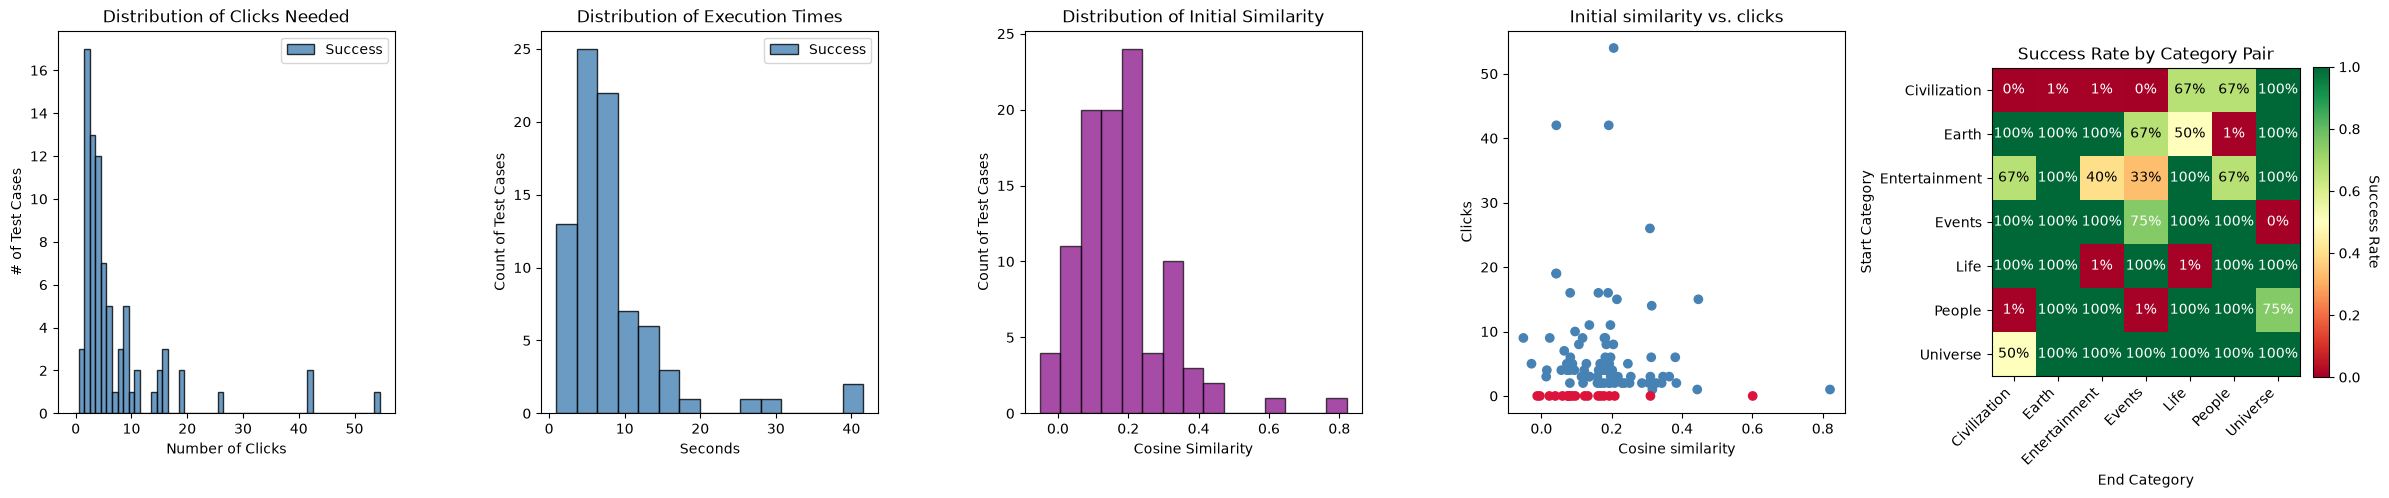

Linear fit: clicks = -9.34 * similarity + 9.05
R^2 = 0.0165  (Only 81 points)


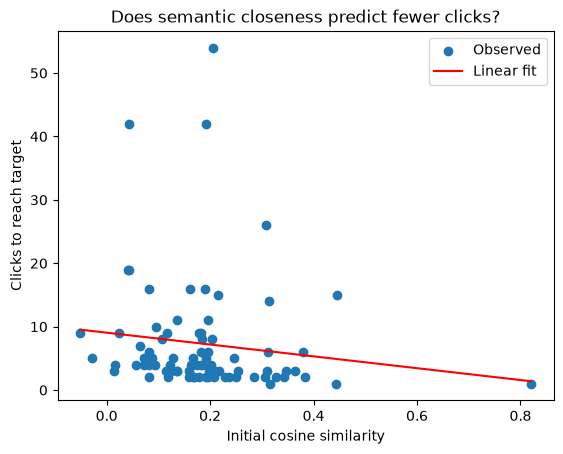

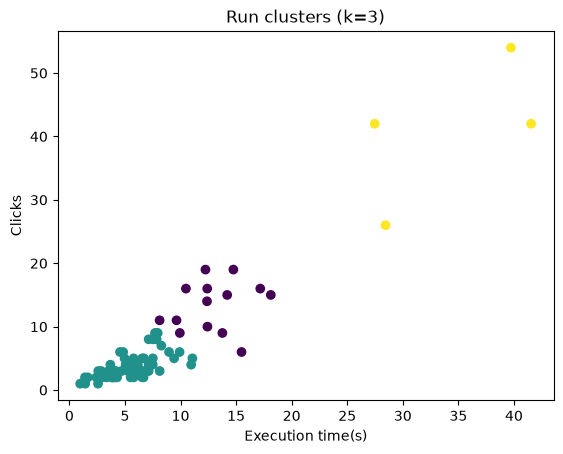

Cluster 0: 'bird' -> 'mount everest' (11 clicks, 9.6s)
Cluster 1: 'earthquake' -> 'long island' (5 clicks, 7.5s)
Cluster 0: 'yom kippur war' -> 'lion' (19 clicks, 14.8s)
Cluster 1: 'queen victoria' -> 'crimea' (2 clicks, 2.9s)
Cluster 0: 'dark matter' -> 'cupid and psyche' (16 clicks, 10.5s)
Cluster 1: 'i ching' -> 'tang dynasty' (1 clicks, 1.0s)
Cluster 0: 'roger federer' -> 'dwayne johnson' (6 clicks, 15.5s)
Cluster 1: 'foo fighters' -> 'mercury (planet)' (3 clicks, 4.7s)
Cluster 1: '2022 fifa world cup' -> 'long island' (2 clicks, 6.6s)
Cluster 1: 'usain bolt' -> 'david beckham' (1 clicks, 2.6s)
Cluster 1: 'syrian civil war' -> 'french revolution' (2 clicks, 5.8s)
Cluster 1: 'list of pornographic actresses by decade' -> 'god' (6 clicks, 9.0s)
Cluster 1: 'netherlands' -> 'dark matter' (8 clicks, 7.5s)
Cluster 1: 'octopus' -> 'tsunami' (2 clicks, 2.4s)
Cluster 1: 'satan' -> 'balkans' (3 clicks, 6.3s)
Cluster 1: 'galaxy' -> 'bird' (2 clicks, 1.7s)
Cluster 1: 'atlantic ocean' -> 'ocean'

In [ ]:
# ---------------------------------------------------------------------------
# Matplotlib visualizations
# ---------------------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score
from sentence_transformers import SentenceTransformer, util
import pickle
import pandas as pd

with open("WikiRacer100.pkl", "rb") as f:
    results = pickle.load(f)

failure_threshold = 60

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def plot_results(results):
    # 1. Convert to DataFrame for easier multi-variable aggregation
    df = pd.DataFrame(pd.read_pickle('WikiRacer100.pkl'))
    
    # Fill missing values just like your original code
    df['clicks'] = df['clicks'].fillna(0)
    df['execution_time'] = df['execution_time'].fillna(0)
    
    # Derive "success" column (opposite of failed)
    df['success'] = ~df['failed']

    # Extract original arrays for your existing plots
    clicks = df['clicks'].to_numpy()
    exec_times = df['execution_time'].to_numpy()
    sims = df['initial_similarity'].to_numpy()
    failed = df['failed'].to_numpy()
    
    successful_clicks = clicks[~failed]
    successful_times = exec_times[~failed]

    # Change to a 1x5 layout to fit the heatmap
    fig, axes = plt.subplots(1, 5, figsize=(24, 5))

    # --- Graph 1: Distribution of Clicks ---
    click_bins = np.arange(0, max(clicks) + 2) - 0.5 
    axes[0].hist([successful_clicks], bins=click_bins, stacked=True, 
                color=["steelblue"], label=["Success"], edgecolor="black", alpha=0.8)
    axes[0].set_title("Distribution of Clicks Needed")
    axes[0].set_xlabel("Number of Clicks")
    axes[0].set_ylabel("# of Test Cases")
    axes[0].legend()

    # --- Graph 2: Distribution of Execution Times ---
    axes[1].hist([successful_times], bins=15, stacked=True,
                color=["steelblue"], label=["Success"], edgecolor="black", alpha=0.8)
    axes[1].set_title("Distribution of Execution Times")
    axes[1].set_xlabel("Seconds")
    axes[1].set_ylabel("Count of Test Cases")
    axes[1].legend()

    # --- Graph 3: Distribution of Initial Similarities ---
    axes[2].hist(sims, bins=15, color="purple", edgecolor="black", alpha=0.7)
    axes[2].set_title("Distribution of Initial Similarity")
    axes[2].set_xlabel("Cosine Similarity")
    axes[2].set_ylabel("Count of Test Cases")

    # --- Graph 4: Scatter Plot ---
    colors = ["crimson" if f else "steelblue" for f in failed]
    axes[3].scatter(sims, clicks, c=colors)
    axes[3].set_title("Initial similarity vs. clicks")
    axes[3].set_xlabel("Cosine similarity")
    axes[3].set_ylabel("Clicks")

    # --- Graph 5: Success Rate Heatmap Given Start and Target category ---
    pivot_df = df.pivot_table(index='start category', columns='target category', values='success', aggfunc='mean')
    
    # Fill missing combinations with 0.00 if no tests ran between those categories
    # 1% just notes empty category run, idk how to put text into a heatmap
    pivot_df = pivot_df.fillna(0.0067)
    
    # Red = Low Success, Yellow = Medium Success, Green = High Success
    im = axes[4].imshow(pivot_df.to_numpy(), cmap='RdYlGn', vmin=0, vmax=1)
    
    # Set categorical text labels
    axes[4].set_xticks(np.arange(len(pivot_df.columns)))
    axes[4].set_yticks(np.arange(len(pivot_df.index)))
    axes[4].set_xticklabels(pivot_df.columns, rotation=45, ha="right")
    axes[4].set_yticklabels(pivot_df.index)
    
    # Annotate percentages
    for i in range(len(pivot_df.index)):
        for j in range(len(pivot_df.columns)):
            val = pivot_df.iloc[i, j]
            axes[4].text(j, i, f"{val:.0%}", ha="center", va="center", 
                            color="black" if 0.3 < val < 0.7 else "white")
    
    axes[4].set_title("Success Rate by Category Pair")
    axes[4].set_xlabel("End Category")
    axes[4].set_ylabel("Start Category")
    
    # Add colorbar specifically for reference
    cbar = fig.colorbar(im, ax=axes[4], fraction=0.046, pad=0.04)
    cbar.set_label('Success Rate', rotation=-90, va="bottom")

    
    plt.tight_layout()
    plt.show()



# ---------------------------------------------------------------------------
# scikit-learn analysis
# ---------------------------------------------------------------------------

def analyze_similarity_vs_clicks(results):
    """Does higher initial similarity actually predict fewer clicks?
    Fits a simple linear regression and reports R^2 - with a small test
    set this is more of a sanity check than a reliable model."""
    successful = [r for r in results if not r["failed"]]
    if len(successful) < 4:
        print("Not enough successful runs to fit a meaningful regression.")
        return

    X = np.array([[r["initial_similarity"]] for r in successful])
    y = np.array([r["clicks"] for r in successful])

    reg = LinearRegression().fit(X, y)
    preds = reg.predict(X)
    r2 = r2_score(y, preds)

    print(f"Linear fit: clicks = {reg.coef_[0]:.2f} * similarity + {reg.intercept_:.2f}")
    print(f"R^2 = {r2:.4f}  (Only {len(successful)} points)")

    plt.scatter(X, y, label="Observed")
    order = X[:, 0].argsort()
    plt.plot(X[order], preds[order], color="red", label="Linear fit")
    plt.xlabel("Initial cosine similarity")
    plt.ylabel("Clicks to reach target")
    plt.legend()
    plt.title("Does semantic closeness predict fewer clicks?")
    plt.show()


def predict_failure_from_similarity(results):
    """Logistic regression: does low initial similarity predict a failed
    (>60s) run? Needs both successes and failures in the data to mean
    anything - check your test set includes some hard pairs."""
    X = np.array([[r["initial_similarity"]] for r in results])
    y = np.array([1 if r["failed"] else 0 for r in results])

    if len(set(y)) < 2:
        print("All runs succeeded (or all failed) - can't fit a classifier "
              "without both classes represented. Add harder/easier test cases.")
        return

    clf = LogisticRegression().fit(X, y)
    print(f"Training accuracy: {clf.score(X, y):.2f} "
          f"(on {len(results)} points - this is not a held-out score)")


def cluster_runs_by_difficulty(results, n_clusters=3):
    """Group test cases by (clicks, execution_time) to see if there are
    natural 'easy/medium/hard' tiers, rather than assuming them."""
    successful = [r for r in results if not r["failed"]]
    if len(successful) < n_clusters:
        print(f"Need at least {n_clusters} successful runs to cluster into "
              f"{n_clusters} groups.")
        return

    features = np.array([[r["execution_time"], r["clicks"]] for r in successful])
    scaled = StandardScaler().fit_transform(features)

    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10).fit(scaled)
    labels = kmeans.labels_

    plt.scatter(features[:, 0], features[:, 1], c=labels, cmap="viridis")
    plt.xlabel("Execution time(s)")
    plt.ylabel("Clicks")
    plt.title(f"Run clusters (k={n_clusters})")
    plt.show()

    for i, r in enumerate(successful):
        print(f"Cluster {labels[i]}: '{r['start']}' -> '{r['target']}' "
              f"({r['clicks']} clicks, {r['execution_time']:.1f}s)")

plot_results(results)
analyze_similarity_vs_clicks(results)
cluster_runs_by_difficulty(results)
predict_failure_from_similarity(results)

# Miscellaneous Data
## Includes: 
Successful/Unsuccessful runs, 
Success Rate, 
Median clicks among successful runs, 
Most difficult run based on initial similarity, 
All failed runs

In [36]:
with open("WikiRacer100.pkl", "rb") as f:
    results = pickle.load(f)
df = pd.DataFrame(pd.read_pickle('WikiRacer100.pkl'))
print(df.columns)
count = (df['failed'] == False).sum()
rows = len(df)
fails = rows-count
print(f'Successful runs: {count}')
print(f'Unsuccessful runs: {fails}')
print(f'Success rate: {count/rows * 100}%')
print(f'Median clicks per run (success only): {df['clicks'].median()}')
print(f'Lowest similarity rate: {df.loc[df['initial_similarity'].idxmin()]}')

print(df.loc[df['failed'] == True, ['start', 'target']])

Index(['start', 'start category', 'target category', 'target',
       'initial_similarity', 'avg_time_per_link', 'execution_time', 'clicks',
       'failed'],
      dtype='str')
Successful runs: 81
Unsuccessful runs: 19
Success rate: 81.0%
Median clicks per run (success only): 4.0
Lowest similarity rate: start                           list of james bond films
start category                                    Events
target category                            Entertainment
target                journey to the center of the earth
initial_similarity                             -0.051244
avg_time_per_link                               0.855828
execution_time                                  7.702455
clicks                                               9.0
failed                                             False
Name: 99, dtype: object
                                                start  \
6                                     second boer war   
12                                    nine 

In [3]:
import pickle

myvar = 'failure_threshold'
with open("myvar.pkl", 'wb') as f:
    pickle.dump(myvar, f)

In [1]:
import pickle 
with open('myvar.pkl', 'rb') as f:
    loaded_data = pickle.load(f)

print(loaded_data)

failure_threshold
